# Otel Rezervasyon İptal Tahmini — Veri Analizi ve Ön İşleme

**Ders:** OYG201 – Yapay Zeka Uygulamaları
**Program:** Ön Yüz Yazılım Geliştirme
**Ödev Danışmanı:** Öğr. Gör. Çisem Yaşar
**Proje Aşaması:** Aşama 1 (%15)
**Öğrenci Adı Soyadı:** Hasan İNCİLER
**Öğrenci No:** 250184009

---

### Projenin Amacı

Bir otelin geçmiş rezervasyon kayıtlarını kullanarak, yeni bir rezervasyonun
**iptal edilip edilmeyeceğini** tahmin eden bir makine öğrenmesi modeli geliştirmek
ve bu modeli bir web arayüzü üzerinden kullanılabilir hale getirmek.

### Veri Seti

| | |
|---|---|
| **Adı** | Hotel Booking Demand |
| **Kaynak** | Kaggle — https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand |
| **Orijinal çalışma** | Antonio, Almeida & Nunes (2019), *Hotel booking demand datasets*, Data in Brief 22, 41–49 |
| **Türü** | Tabüler (CSV) |
| **Hedef değişken** | `is_canceled` (0 = iptal edilmedi, 1 = iptal edildi) |
| **Problem türü** | İkili sınıflandırma (binary classification) |

### Bu Notebook'ta Yapılanlar

1. Veri setinin yapısının incelenmesi
2. Eksik verilerin tespiti ve sütun bazında işlenmesi
3. Veri sızıntısına (data leakage) yol açan sütunların çıkarılması
4. Kategorik değişkenlerin sayısal verilere dönüştürülmesi
5. **5 farklı görselleştirme** ile veri yapısının ve sınıf dağılımının incelenmesi

## 1. Kütüphanelerin Yüklenmesi

In [1]:
# Veri işleme kütüphanesi
import pandas as pd

# Görselleştirme kütüphanesi (derste kullandığımız pyplot modülü)
import matplotlib.pyplot as plt

# Pandas'ın geniş tabloları kesmeden göstermesi için
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("Kütüphaneler yüklendi.")
print("pandas sürümü:", pd.__version__)

Kütüphaneler yüklendi.
pandas sürümü: 3.0.5


## 2. Veri Setinin Yüklenmesi

Veri seti Kaggle kaynaklıdır. Colab üzerinde her seferinde Kaggle API anahtarı
gerektirmemesi için, aynı veri setinin herkese açık bir kopyası doğrudan URL
üzerinden okunmaktadır.

In [2]:
# Veri setinin herkese açık kopyası (Kaggle'daki "Hotel Booking Demand" ile aynı dosya)
VERI_URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"

# CSV dosyasını bir pandas DataFrame'e okuyoruz
df = pd.read_csv(VERI_URL)

# Ham veriyi daha sonra karşılaştırma yapabilmek için ayrı bir kopyada saklıyoruz
df_ham = df.copy()

print(f"Veri seti yüklendi.")
print(f"Satır sayısı (örnek sayısı)      : {df.shape[0]:,}")
print(f"Sütun sayısı (öznitelik sayısı)  : {df.shape[1]}")

Veri seti yüklendi.
Satır sayısı (örnek sayısı)      : 119,390
Sütun sayısı (öznitelik sayısı)  : 32


### 2.1. Veri Setinin İlk 5 Satırı

In [3]:
# Verinin genel görünümünü anlamak için ilk 5 satıra bakıyoruz
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### 2.2. Sütun Türleri ve Dolu Değer Sayıları

`info()` bize her sütunun veri tipini (sayısal/metinsel) ve kaç adet dolu değer
içerdiğini verir. Dolu değer sayısı 119.390'dan küçük olan sütunlarda eksik veri vardır.

In [4]:
# Sütun türleri ve dolu (non-null) değer sayıları
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

### 2.3. Sayısal Sütunların Betimsel İstatistikleri

In [5]:
# Sayısal sütunların ortalama, standart sapma, min-max ve çeyreklik değerleri
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


### 2.4. Sayısal ve Kategorik Sütunların Ayrılması

In [6]:
# Sütunları veri tiplerine göre iki gruba ayırıyoruz
sayisal_sutunlar   = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
kategorik_sutunlar = df.select_dtypes(include=["object", "string"]).columns.tolist()

print(f"Sayısal sütun sayısı   : {len(sayisal_sutunlar)}")
print(f"Kategorik sütun sayısı : {len(kategorik_sutunlar)}")
print()
print("Kategorik sütunlar ve kaç farklı değer (benzersiz kategori) içerdikleri:")
print("-" * 60)
for sutun in kategorik_sutunlar:
    print(f"  {sutun:30s} -> {df[sutun].nunique():4d} farklı değer")

Sayısal sütun sayısı   : 20
Kategorik sütun sayısı : 12

Kategorik sütunlar ve kaç farklı değer (benzersiz kategori) içerdikleri:
------------------------------------------------------------
  hotel                          ->    2 farklı değer
  arrival_date_month             ->   12 farklı değer
  meal                           ->    5 farklı değer
  country                        ->  177 farklı değer
  market_segment                 ->    8 farklı değer
  distribution_channel           ->    5 farklı değer
  reserved_room_type             ->   10 farklı değer
  assigned_room_type             ->   12 farklı değer
  deposit_type                   ->    3 farklı değer
  customer_type                  ->    4 farklı değer
  reservation_status             ->    3 farklı değer
  reservation_status_date        ->  926 farklı değer


## 3. Eksik Verilerin (null/nan) İncelenmesi

Hangi sütunda ne kadar eksik veri olduğunu tespit ediyoruz. Eksik veri oranı,
o sütuna uygulanacak stratejiyi doğrudan belirler.

In [7]:
# Her sütundaki eksik değer sayısı ve oranını bir tabloda topluyoruz
eksik_sayi  = df.isna().sum()
eksik_oran  = (df.isna().sum() / len(df) * 100).round(3)

eksik_tablo = pd.DataFrame({
    "Eksik Değer Sayısı": eksik_sayi,
    "Eksik Oranı (%)": eksik_oran
})

# Sadece eksik verisi olan sütunları, oranı büyükten küçüğe sıralayarak gösteriyoruz
eksik_tablo = eksik_tablo[eksik_tablo["Eksik Değer Sayısı"] > 0]
eksik_tablo = eksik_tablo.sort_values("Eksik Değer Sayısı", ascending=False)

print("EKSİK VERİ İÇEREN SÜTUNLAR")
print("=" * 50)
display(eksik_tablo)

print(f"\nEksik veri içeren sütun sayısı : {len(eksik_tablo)} / {df.shape[1]}")

EKSİK VERİ İÇEREN SÜTUNLAR


,Eksik Değer Sayısı,Eksik Oranı (%)
company,112593,94.307
agent,16340,13.686
country,488,0.409
children,4,0.003



Eksik veri içeren sütun sayısı : 4 / 32


### Grafik 1 — Eksik Veri Oranları (Yatay Çubuk)

Sütun adları uzun olduğu için derste öğrendiğimiz kurala uyup **yatay çubuk** (`plt.barh`) kullanıyoruz.

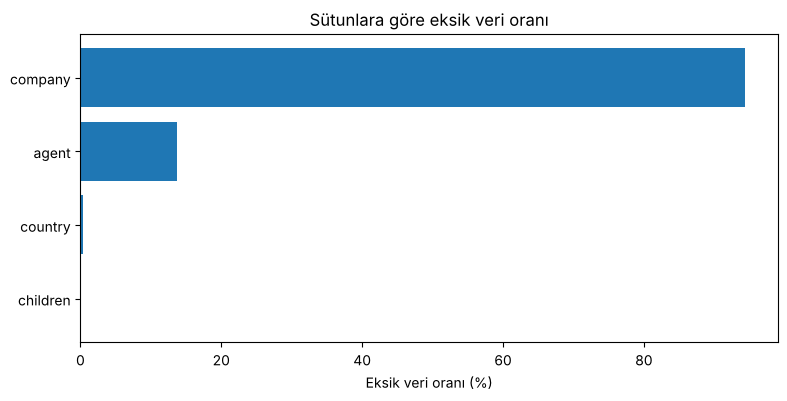

In [8]:
# Eksik oranlarını küçükten büyüğe sıralıyoruz (çubuklar düzenli görünsün diye)
eksik_oranlari = eksik_tablo["Eksik Oranı (%)"].sort_values()

plt.figure(figsize=(9, 4))
plt.barh(eksik_oranlari.index, eksik_oranlari.values)   # yatay çubuk
plt.title("Sütunlara göre eksik veri oranı")
plt.xlabel("Eksik veri oranı (%)")
plt.show()

# 1) Eksik veri sadece 4 sütunda var, diğer 28 sütun tam dolu.
# 2) company sütununun neredeyse tamamı boş (%94,31).
# 3) country ve children'daki eksiklik o kadar az ki çubukları görünmüyor.

**Grafik 1 Yorumu:**

Eksik veri yalnızca 4 sütunda görülmektedir ve bu sütunların eksiklik düzeyleri birbirinden çok farklıdır:

- `company` sütununun **%94,31**'i eksiktir. Bu sütun rezervasyonu yapan şirketin numarasını tutar.
  Eksikliğin bu kadar yüksek olması tesadüf değildir: rezervasyonların çoğu bireysel müşteriler
  tarafından yapılmış, dolayısıyla şirket bilgisi hiç girilmemiştir.
- `agent` sütununun **%13,69**'u eksiktir; bu da rezervasyonun bir seyahat acentesi aracılığıyla
  yapılmadığı anlamına gelir.
- `country` (**%0,41**) ve `children` (**%0,003**) sütunlarındaki eksiklik ihmal edilebilir düzeydedir
  ve gerçek bir veri girişi hatasına işaret eder.

Buradan çıkan sonuç şudur: `company` ve `agent` sütunlarındaki eksiklik **rastgele bir kayıp değil,
anlamlı bir bilgidir** ("şirket yok" / "acente yok"). Bu nedenle bu sütunlar ortalama ile
doldurulmamalı, eksiklik kendi başına bir kategori olarak değerlendirilmelidir.

## 4. Eksik Verilerin İşlenmesi

Yukarıdaki analiz doğrultusunda her sütun için **ayrı ve gerekçeli** bir strateji uyguluyoruz.

| Sütun | Eksik Oranı | Uygulanacak Strateji | Gerekçe |
|---|---|---|---|
| `company` | %94,31 | Sütun tamamen çıkarılır | Verinin %94'ü eksik olduğu için modele anlamlı katkı sağlayamaz; doldurulması yapay bilgi üretir |
| `agent` | %13,69 | `0` ile doldurulur ("acente yok") | Eksiklik, acente kullanılmadığını ifade eden anlamlı bir bilgidir |
| `country` | %0,41 | Mod (en sık görülen ülke) ile doldurulur | Eksik oran çok düşük; kategorik sütun olduğu için ortalama/medyan kullanılamaz |
| `children` | %0,003 | `0` ile doldurulur | Sadece 4 satır eksiktir; çocuk sayısının bildirilmemesi çocuk olmadığı anlamına gelir |

In [9]:
print("İŞLEM ÖNCESİ toplam eksik değer sayısı:", df.isna().sum().sum())
print("İşlem öncesi boyut:", df.shape)
print("-" * 55)

# 1) company: %94 eksik -> sütunu tamamen çıkarıyoruz
df = df.drop(columns=["company"])
print("1) 'company' sütunu çıkarıldı (eksik oranı %94,31 olduğu için).")

# 2) agent: eksiklik "acente kullanılmadı" demek -> 0 ile dolduruyoruz
df["agent"] = df["agent"].fillna(0)
print("2) 'agent' sütunundaki eksik değerler 0 ile dolduruldu ('acente yok').")

# 3) country: kategorik sütun -> mod (en sık görülen değer) ile dolduruyoruz
ulke_modu = df["country"].mode()[0]
df["country"] = df["country"].fillna(ulke_modu)
print(f"3) 'country' sütunundaki eksik değerler mod ile dolduruldu (mod = '{ulke_modu}').")

# 4) children: 4 satır eksik -> 0 ile dolduruyoruz
df["children"] = df["children"].fillna(0).astype(int)
print("4) 'children' sütunundaki eksik değerler 0 ile dolduruldu.")

print("-" * 55)
print("İŞLEM SONRASI toplam eksik değer sayısı:", df.isna().sum().sum())
print("İşlem sonrası boyut:", df.shape)

İŞLEM ÖNCESİ toplam eksik değer sayısı: 129425
İşlem öncesi boyut: (119390, 32)
-------------------------------------------------------
1) 'company' sütunu çıkarıldı (eksik oranı %94,31 olduğu için).
2) 'agent' sütunundaki eksik değerler 0 ile dolduruldu ('acente yok').
3) 'country' sütunundaki eksik değerler mod ile dolduruldu (mod = 'PRT').
4) 'children' sütunundaki eksik değerler 0 ile dolduruldu.
-------------------------------------------------------
İŞLEM SONRASI toplam eksik değer sayısı: 0
İşlem sonrası boyut: (119390, 31)


## 5. Veri Sızıntısına (Data Leakage) Yol Açan Sütunların Çıkarılması

Veri setinde, tahmin yapmaya çalıştığımız sonucun **kendisini içeren** iki sütun bulunmaktadır.
Bu sütunlar modele verilirse model %100'e yakın doğruluk gösterir, ancak gerçek hayatta
hiçbir işe yaramaz — çünkü bu bilgiler ancak rezervasyon sonuçlandıktan *sonra* oluşur.
Tahmin anında ise bu bilgiler henüz mevcut değildir.

In [10]:
# reservation_status sütununun hedef değişkenle ilişkisini inceleyelim
print("reservation_status sütunundaki değerler:")
print(df["reservation_status"].value_counts())
print()
print("reservation_status ile is_canceled çapraz tablosu:")
print(pd.crosstab(df["reservation_status"], df["is_canceled"]))

reservation_status sütunundaki değerler:
reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64

reservation_status ile is_canceled çapraz tablosu:
is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207


Çapraz tablo sorunu açıkça göstermektedir: `reservation_status` sütunu `Canceled`
veya `No-Show` değerini aldığında hedef değişken **her zaman** 1, `Check-Out`
değerini aldığında **her zaman** 0'dır. Yani bu sütun hedef değişkenin birebir
kopyasıdır. Aynı şekilde `reservation_status_date` de rezervasyon sonuçlandıktan
sonra oluşan bir tarihtir.

Bu iki sütun modelden çıkarılmalıdır.

In [11]:
# Veri sızıntısına yol açan sütunları çıkarıyoruz
sizinti_sutunlari = ["reservation_status", "reservation_status_date"]
df = df.drop(columns=sizinti_sutunlari)

print("Çıkarılan sütunlar:", sizinti_sutunlari)
print("Güncel boyut:", df.shape)

Çıkarılan sütunlar: ['reservation_status', 'reservation_status_date']
Güncel boyut: (119390, 29)


## 6. Görselleştirmeler

Veri setinin yapısını ve sınıf dağılımlarını incelemek için farklı türde grafikler kullanıyoruz.

### Grafik 2 — Hedef Değişkenin Sınıf Dağılımı (Çubuk)

Derste `value_counts()` sonucunu doğrudan `plt.bar`'a verdiğimiz gibi, hedef değişkenin
sınıflarını da aynı şekilde çiziyoruz. Sınıflar arasındaki denge, hangi başarı ölçütünü
kullanacağımızı belirler.

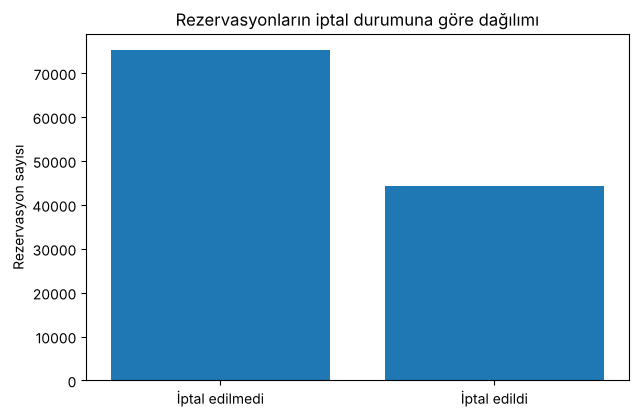

İptal edilmedi  : 75,166 rezervasyon  (%62.96)
İptal edildi    : 44,224 rezervasyon  (%37.04)


In [12]:
# Hedef değişkendeki her sınıfın kaç kez geçtiğini sayıyoruz
sinif_sayilari = df["is_canceled"].value_counts().sort_index()

plt.figure(figsize=(7, 4.5))
plt.bar(["İptal edilmedi", "İptal edildi"], sinif_sayilari.values)
plt.title("Rezervasyonların iptal durumuna göre dağılımı")
plt.ylabel("Rezervasyon sayısı")
plt.show()

# Sayıları ve yüzdeleri de yazdıralım
toplam = len(df)
for sinif, adet in sinif_sayilari.items():
    ad = "İptal edilmedi" if sinif == 0 else "İptal edildi"
    print(f"{ad:16s}: {adet:,} rezervasyon  (%{adet / toplam * 100:.2f})")

**Grafik 2 Yorumu:**

Rezervasyonların **%62,96**'sı iptal edilmemiş, **%37,04**'ü iptal edilmiştir. Sınıflar arasındaki
oran yaklaşık **1,70 : 1**'dir; yani **ılımlı düzeyde dengesiz (imbalanced)** bir veri setidir.

Bunun iki önemli sonucu vardır:

1. **Doğruluk (accuracy) tek başına yeterli bir ölçüt değildir.** Hiçbir şey öğrenmeyen ve her
   rezervasyon için "iptal edilmeyecek" diyen bir model dahi %62,96 doğruluk elde eder. Bu nedenle
   Aşama 2'de modeli değerlendirirken **precision, recall ve F1-skoru** da raporlanacaktır.
2. Dengesizlik şiddetli olmadığı için (örneğin 100:1 gibi değil) yeniden örnekleme teknikleri
   zorunlu değildir; model eğitiminde sınıf ağırlıklarının dengelenmesi yeterli olacaktır.

Olumlu yönden, iptal edilen 44.224 rezervasyon, modelin azınlık sınıfını öğrenmesi için yeterli
sayıda örnek bulunduğunu göstermektedir.

### Grafik 3 — Bekleme Süresinin Dağılımı (Histogram)

`lead_time`, rezervasyonun yapıldığı tarih ile otele giriş tarihi arasındaki gün sayısıdır.
Histogram, bu sayısal değerlerin hangi aralıkta yoğunlaştığını gösterir. İki sınıfı aynı eksende
üst üste çizip ortalamayı derste öğrendiğimiz `plt.axvline` ile işaretliyoruz.

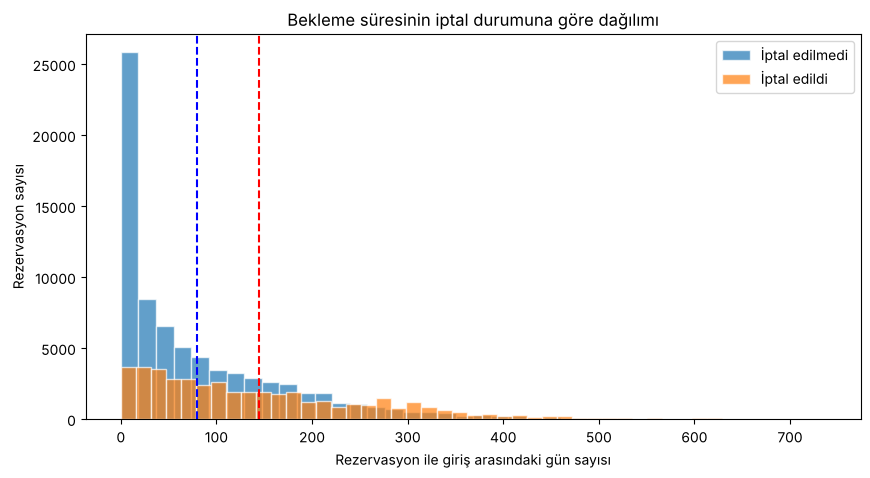

Ortalama bekleme süresi (gün):
  İptal edilmeyenler: 80
  İptal edilenler   : 145


In [13]:
# İptal edilen ve edilmeyen rezervasyonların bekleme sürelerini ayrı ayrı alıyoruz
iptal_edilmeyen = df[df["is_canceled"] == 0]["lead_time"]
iptal_edilen    = df[df["is_canceled"] == 1]["lead_time"]

plt.figure(figsize=(10, 5))
# alpha: çubukları yarı saydam yapar, üst üste binince ikisi de görünür
plt.hist(iptal_edilmeyen, bins=40, edgecolor="white", alpha=0.7, label="İptal edilmedi")
plt.hist(iptal_edilen,    bins=40, edgecolor="white", alpha=0.7, label="İptal edildi")

# İki grubun ortalamalarını dikey kesikli çizgiyle gösteriyoruz
plt.axvline(iptal_edilmeyen.mean(), color="blue", linestyle="--")
plt.axvline(iptal_edilen.mean(),    color="red",  linestyle="--")

plt.title("Bekleme süresinin iptal durumuna göre dağılımı")
plt.xlabel("Rezervasyon ile giriş arasındaki gün sayısı")
plt.ylabel("Rezervasyon sayısı")
plt.legend()
plt.show()

print("Ortalama bekleme süresi (gün):")
print(f"  İptal edilmeyenler: {iptal_edilmeyen.mean():.0f}")
print(f"  İptal edilenler   : {iptal_edilen.mean():.0f}")

**Grafik 3 Yorumu:**

Her iki sınıfın dağılımı da **sağa çarpıktır**: rezervasyonların büyük bölümü girişten kısa süre
önce yapılmıştır. Ancak iki sınıf arasında belirgin bir fark vardır. İptal edilmeyen rezervasyonlar
0-50 gün aralığında yoğunlaşmakta; bekleme süresi arttıkça iptal edilenlerin payı yükselmektedir.
Kesikli çizgiler de bunu doğrular: ortalama bekleme süresi iptal edilmeyenlerde yaklaşık **80 gün**,
iptal edilenlerde yaklaşık **145 gün**'dür.

Bu bulgu sezgisel olarak da anlamlıdır: bir müşteri rezervasyonunu ne kadar erken yaparsa, giriş
tarihine kadar planlarının değişmesi için o kadar çok zaman geçer.

**Modelleme açısından sonuç:** `lead_time`, iptal tahmininde **en güçlü ayırt edici özniteliklerden
biri** olacaktır.

### Grafik 4 — Pazar Segmentine Göre İptal Oranları (Yatay Çubuk)

Kategorik bir değişkenin hedefle ilişkisini inceliyoruz. Segment adları uzun olduğu için yine
yatay çubuk kullanıyoruz. Ortalamayı `plt.axvline` ile işaretleyerek hangi segmentlerin ortalamanın
üstünde kaldığını görünür kılıyoruz.

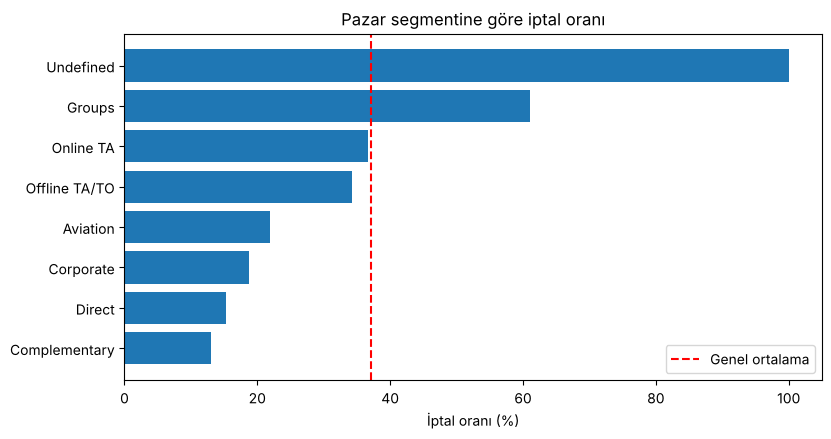

Segment bazında iptal oranı (%) ve rezervasyon sayısı:
                iptal_orani  rezervasyon_sayisi
market_segment                                 
Undefined             100.0                   2
Groups                 61.1               19811
Online TA              36.7               56477
Offline TA/TO          34.3               24219
Aviation               21.9                 237
Corporate              18.7                5295
Direct                 15.3               12606
Complementary          13.1                 743


In [14]:
# groupby ile her pazar segmentinin ortalama iptal oranını buluyoruz.
# is_canceled sütunu 0 ve 1'lerden oluştuğu için ortalaması doğrudan iptal oranını verir.
segment_iptal = df.groupby("market_segment")["is_canceled"].mean().sort_values() * 100
genel_ortalama = df["is_canceled"].mean() * 100

plt.figure(figsize=(9, 4.5))
plt.barh(segment_iptal.index, segment_iptal.values)
plt.axvline(genel_ortalama, color="red", linestyle="--", label="Genel ortalama")
plt.title("Pazar segmentine göre iptal oranı")
plt.xlabel("İptal oranı (%)")
plt.legend()
plt.show()

print("Segment bazında iptal oranı (%) ve rezervasyon sayısı:")
print(df.groupby("market_segment")["is_canceled"].agg(
    iptal_orani=lambda s: round(s.mean() * 100, 1),
    rezervasyon_sayisi="size").sort_values("iptal_orani", ascending=False))

**Grafik 4 Yorumu:**

Grafiğin en üstündeki `Undefined` segmenti %100 iptal oranıyla göze çarpmaktadır; ancak bu segmentte
**yalnızca 2 rezervasyon** bulunmaktadır. Bu kadar az örnekten güvenilir bir sonuç çıkarılamaz, bu
nedenle değerlendirmeye alınmamıştır. Bu aynı zamanda bir uyarıdır: oran grafiklerinde yüzdeye
bakmadan önce o kategoride kaç örnek olduğuna bakmak gerekir.

Anlamlı büyüklükteki segmentlere bakıldığında iptal oranı **çok güçlü biçimde değişmektedir**:

- `Groups` (grup rezervasyonları) segmentinde iptal oranı **%61,1**'dir. Grup rezervasyonları
  genellikle tur operatörleri tarafından ön tedbir amaçlı yapıldığı ve sonradan kolayca iptal
  edilebildiği için bu beklenen bir sonuçtur.
- `Online TA` (çevrimiçi seyahat acentesi) **%36,7** ile genel ortalamaya yakındır, ancak 56.477
  rezervasyonla veri setindeki en büyük segment olduğu için modelin genel başarısında belirleyici
  olacaktır.
- `Direct` (doğrudan rezervasyon) **%15,3** ve `Complementary` **%13,1** ile en düşük oranlara
  sahiptir. Doğrudan otelle iletişime geçen müşterilerin kararlılığı daha yüksektir.

Bu dağılım, iptal davranışının rastgele olmadığını, rezervasyonun yapılış kanalıyla sistematik
biçimde ilişkili olduğunu göstermektedir. Yani `market_segment` model için değerli bir özniteliktir.

### Grafik 5 — Bekleme Süresi ile Oda Fiyatı İlişkisi (Saçılım)

Son olarak iki sayısal değişken arasındaki ilişkiye bakıyoruz: bekleme süresi (`lead_time`) ve
günlük ortalama oda fiyatı (`adr`). Her rezervasyon bir nokta olacak; derste öğrendiğimiz
`groupby` döngüsüyle iptal edilenleri ve edilmeyenleri **farklı renkte** çizeceğiz.

119.390 noktanın hepsini çizmek grafiği okunmaz bir leke haline getirdiği için rastgele 1.000
rezervasyonluk bir örneklem kullanıyoruz.

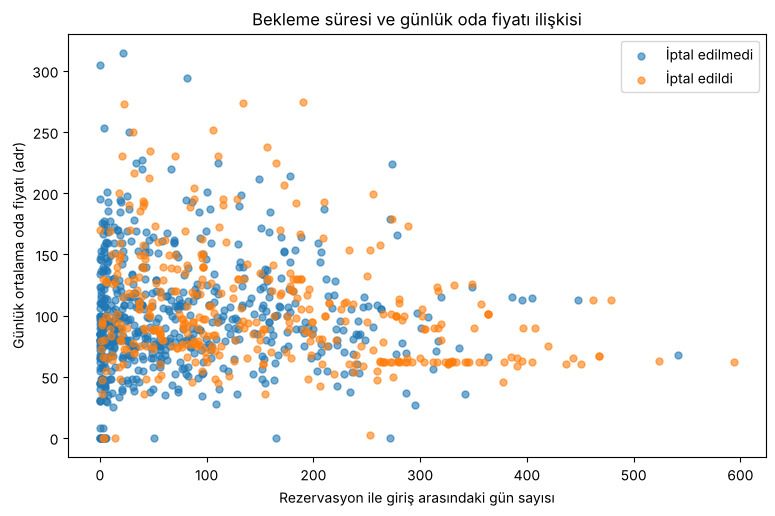

is_canceled ile korelasyonlar:
total_of_special_requests     -0.23
required_car_parking_spaces   -0.20
booking_changes               -0.14
is_repeated_guest             -0.08
adr                            0.05
previous_cancellations         0.11
lead_time                      0.29
dtype: float64


In [15]:
# Rastgele 1000 rezervasyon seçiyoruz.
# random_state: her çalıştırmada aynı örneklemin gelmesini sağlar (sonuçlar tekrarlanabilir olsun diye)
ornek = df.sample(1000, random_state=42)

etiketler = {0: "İptal edilmedi", 1: "İptal edildi"}

plt.figure(figsize=(9, 5.5))
# Derste öğrendiğimiz groupby döngüsü: her sınıf ayrı renkte çizilir
for durum, grup in ornek.groupby("is_canceled"):
    plt.scatter(grup["lead_time"], grup["adr"],
                label=etiketler[durum], s=25, alpha=0.6)

plt.title("Bekleme süresi ve günlük oda fiyatı ilişkisi")
plt.xlabel("Rezervasyon ile giriş arasındaki gün sayısı")
plt.ylabel("Günlük ortalama oda fiyatı (adr)")
plt.legend()
plt.show()

# Grafikte görülen örtüşmeyi sayısal olarak da kontrol edelim:
# her özniteliğin hedef değişkenle korelasyonu
sayisal_sutunlar = ["lead_time", "adr", "total_of_special_requests",
                    "required_car_parking_spaces", "booking_changes",
                    "previous_cancellations", "is_repeated_guest"]
korelasyonlar = df[sayisal_sutunlar].corrwith(df["is_canceled"]).round(2)

print("is_canceled ile korelasyonlar:")
print(korelasyonlar.sort_values())

**Grafik 5 Yorumu:**

Grafikte iki sınıfın noktaları **büyük ölçüde iç içe geçmiştir**. Sağ tarafta (uzun bekleme süresi)
turuncu noktaların yoğunluğu artmakta, yani Grafik-3'teki bulgu burada da görülmektedir. Ancak
grafiğin üzerine çizilebilecek **tek bir düz çizgi iki sınıfı ayıramaz**.

Bu gözlem, altındaki korelasyon çıktısıyla da uyumludur: hedef değişkenle en güçlü ilişkiye sahip
öznitelik `lead_time`'dır (**+0,29**), onu özel talep sayısı (**-0,23**) ve ayrılan otopark yeri
sayısı (**-0,20**) izler. Negatif ilişkiler anlamlıdır: özel talepte bulunan veya otopark yeri
ayırtan bir müşteri konaklamasını somutlaştırmış, dolayısıyla kararlılığı yüksek bir müşteridir.

**En önemli sonuç:** hiçbir tek öznitelik hedef değişkenle 0,30'un üzerinde korelasyona sahip
değildir. Yani iptal davranışı tek bir değişkenle açıklanamaz; **öznitelikler arasındaki
etkileşimlerden** kaynaklanmaktadır. Bu nedenle Aşama 2'de yalnızca Lojistik Regresyon gibi doğrusal
bir modelle yetinilmemeli, **Rastgele Orman ve XGBoost gibi doğrusal olmayan modeller** de
denenmelidir. Bu grafik, o model seçimi kararının gerekçesidir.

## 7. Kategorik Değişkenlerin Sayısal Verilere Dönüştürülmesi

Makine öğrenmesi algoritmaları metinsel verilerle çalışamaz; tüm öznitelikler sayısal
olmalıdır. Ancak **tek bir dönüştürme yöntemi tüm sütunlar için uygun değildir**.
Yöntem seçimi, sütunun kaç farklı kategori içerdiğine (kardinalite) bağlıdır.

In [16]:
# Kategorik sütunları kardinalitelerine göre listeleyelim
kategorik_sutunlar = df.select_dtypes(include=["object", "string"]).columns.tolist()

print("Kategorik sütunlar ve kardinaliteleri:")
print("-" * 50)
for sutun in sorted(kategorik_sutunlar, key=lambda s: df[s].nunique(), reverse=True):
    print(f"  {sutun:25s} -> {df[sutun].nunique():4d} farklı değer")

Kategorik sütunlar ve kardinaliteleri:
--------------------------------------------------
  country                   ->  177 farklı değer
  arrival_date_month        ->   12 farklı değer
  assigned_room_type        ->   12 farklı değer
  reserved_room_type        ->   10 farklı değer
  market_segment            ->    8 farklı değer
  meal                      ->    5 farklı değer
  distribution_channel      ->    5 farklı değer
  customer_type             ->    4 farklı değer
  deposit_type              ->    3 farklı değer
  hotel                     ->    2 farklı değer


### Uygulanacak Dönüştürme Stratejisi

| Sütun | Kategori Sayısı | Yöntem | Gerekçe |
|---|---|---|---|
| `country` | 177 | **Frekans kodlama** (frequency encoding) | One-hot encoding 177 yeni sütun oluşturur ve "boyut felaketine" (curse of dimensionality) yol açar. Her ülke, veri setinde görülme sıklığı ile temsil edilir. |
| `arrival_date_month` | 12 | **Sıralı kodlama** (ordinal encoding) | Aylar doğal bir sıraya sahiptir (Ocak=1 … Aralık=12). Bu sıra bilgisi korunmalıdır. |
| `hotel`, `meal`, `market_segment`, `distribution_channel`, `reserved_room_type`, `assigned_room_type`, `deposit_type`, `customer_type` | 2–12 | **One-hot encoding** | Bu kategoriler arasında doğal bir büyüklük sırası yoktur. Label encoding kullanılsaydı model, örneğin "Direct > Online TA" gibi var olmayan bir sıralama varsayardı. |

**Not:** One-hot encoding uygulanırken `drop_first=True` parametresi kullanılacaktır.
Bu, her sütundan bir kategoriyi referans olarak çıkararak gereksiz tekrarı
(kukla değişken tuzağı / dummy variable trap) önler.

In [17]:
# İşlem öncesi boyutu kaydediyoruz
boyut_once = df.shape
print("Dönüştürme öncesi boyut:", boyut_once)
print("=" * 60)

# --- 1) country: frekans kodlama (177 kategori) ---
ulke_frekanslari = df["country"].value_counts(normalize=True)
df["country_frekans"] = df["country"].map(ulke_frekanslari)
df = df.drop(columns=["country"])
print(f"1) 'country' (177 kategori) -> frekans kodlama ile tek sayısal sütuna çevrildi.")

# --- 2) arrival_date_month: sıralı kodlama (aylar doğal sıraya sahip) ---
ay_sirasi = {
    "January": 1, "February": 2, "March": 3, "April": 4,
    "May": 5, "June": 6, "July": 7, "August": 8,
    "September": 9, "October": 10, "November": 11, "December": 12
}
df["arrival_date_month"] = df["arrival_date_month"].map(ay_sirasi)
print("2) 'arrival_date_month' -> sıralı kodlama ile 1-12 arası sayılara çevrildi.")

# --- 3) Kalan kategorik sütunlar: one-hot encoding ---
kalan_kategorik = df.select_dtypes(include=["object", "string"]).columns.tolist()
print(f"3) One-hot encoding uygulanacak sütunlar: {kalan_kategorik}")

df = pd.get_dummies(df, columns=kalan_kategorik, drop_first=True, dtype=int)

print("=" * 60)
print("Dönüştürme sonrası boyut:", df.shape)
print(f"Sütun sayısı {boyut_once[1]} -> {df.shape[1]} oldu (+{df.shape[1] - boyut_once[1]} yeni sütun).")
print()
print("Kalan metinsel (object) sütun sayısı:", len(df.select_dtypes(include=["object", "string"]).columns))

Dönüştürme öncesi boyut: (119390, 29)
1) 'country' (177 kategori) -> frekans kodlama ile tek sayısal sütuna çevrildi.
2) 'arrival_date_month' -> sıralı kodlama ile 1-12 arası sayılara çevrildi.
3) One-hot encoding uygulanacak sütunlar: ['hotel', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type']


Dönüştürme sonrası boyut: (119390, 62)
Sütun sayısı 29 -> 62 oldu (+33 yeni sütun).

Kalan metinsel (object) sütun sayısı: 0


### 7.1. Dönüştürme Sonrası Veri Setinin Kontrolü

In [18]:
# Tüm sütunların sayısal olduğunu doğruluyoruz
print("Veri tiplerinin dağılımı:")
print(df.dtypes.value_counts())
print()
print("Toplam eksik değer sayısı:", df.isna().sum().sum())
print()

# İlk 5 satırın son hali
print("Ön işleme tamamlanmış veri setinin ilk 5 satırı:")
display(df.head())

Veri tiplerinin dağılımı:
int64      59
float64     3
Name: count, dtype: int64

Toplam eksik değer sayısı: 0

Ön işleme tamamlanmış veri setinin ilk 5 satırı:


,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,country_frekans,hotel_Resort Hotel,meal_FB,meal_HB,meal_SC,meal_Undefined,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,market_segment_Undefined,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,distribution_channel_Undefined,reserved_room_type_B,reserved_room_type_C,reserved_room_type_D,reserved_room_type_E,reserved_room_type_F,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,reserved_room_type_P,assigned_room_type_B,assigned_room_type_C,assigned_room_type_D,assigned_room_type_E,assigned_room_type_F,assigned_room_type_G,assigned_room_type_H,assigned_room_type_I,assigned_room_type_K,assigned_room_type_L,assigned_room_type_P,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
0,0,342,2015,7,27,1,0,0,2,0,0,0,0,0,3,0.0,0,0.0,0,0,0.411073,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0
1,0,737,2015,7,27,1,0,0,2,0,0,0,0,0,4,0.0,0,0.0,0,0,0.411073,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0
2,0,7,2015,7,27,1,0,1,1,0,0,0,0,0,0,0.0,0,75.0,0,0,0.101591,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0
3,0,13,2015,7,27,1,0,1,1,0,0,0,0,0,0,304.0,0,75.0,0,0,0.101591,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4,0,14,2015,7,27,1,0,2,2,0,0,0,0,0,0,240.0,0,98.0,0,1,0.101591,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0


## 8. Ön İşleme Özeti

In [19]:
print("=" * 62)
print("            ÖN İŞLEME ÖZETİ")
print("=" * 62)
print(f"Ham veri seti boyutu              : {df_ham.shape[0]:,} satır x {df_ham.shape[1]} sütun")
print(f"İşlenmiş veri seti boyutu         : {df.shape[0]:,} satır x {df.shape[1]} sütun")
print(f"Ham veri setindeki eksik değer    : {df_ham.isna().sum().sum():,}")
print(f"İşlenmiş veri setindeki eksik değer: {df.isna().sum().sum()}")
print("-" * 62)
print("Uygulanan işlemler:")
print("  1. 'company' sütunu çıkarıldı (%94,31 eksik)")
print("  2. 'agent' sütunu 0 ile dolduruldu ('acente yok')")
print("  3. 'country' sütunu mod ile dolduruldu")
print("  4. 'children' sütunu 0 ile dolduruldu")
print("  5. Veri sızıntısı yapan 2 sütun çıkarıldı")
print("     ('reservation_status', 'reservation_status_date')")
print("  6. 'country' frekans kodlama ile sayısallaştırıldı")
print("  7. 'arrival_date_month' sıralı kodlama ile sayısallaştırıldı")
print("  8. Kalan 8 kategorik sütuna one-hot encoding uygulandı")
print("-" * 62)
print(f"Hedef değişken (is_canceled) dağılımı:")
print(f"  Sınıf 0 (iptal edilmedi) : {(df['is_canceled']==0).sum():,}  (%{(df['is_canceled']==0).mean()*100:.2f})")
print(f"  Sınıf 1 (iptal edildi)   : {(df['is_canceled']==1).sum():,}  (%{(df['is_canceled']==1).mean()*100:.2f})")
print("=" * 62)
print()
print("Veri seti, Aşama 2'de model eğitimi için hazır durumdadır.")

            ÖN İŞLEME ÖZETİ
Ham veri seti boyutu              : 119,390 satır x 32 sütun
İşlenmiş veri seti boyutu         : 119,390 satır x 62 sütun
Ham veri setindeki eksik değer    : 129,425
İşlenmiş veri setindeki eksik değer: 0
--------------------------------------------------------------
Uygulanan işlemler:
  1. 'company' sütunu çıkarıldı (%94,31 eksik)
  2. 'agent' sütunu 0 ile dolduruldu ('acente yok')
  3. 'country' sütunu mod ile dolduruldu
  4. 'children' sütunu 0 ile dolduruldu
  5. Veri sızıntısı yapan 2 sütun çıkarıldı
     ('reservation_status', 'reservation_status_date')
  6. 'country' frekans kodlama ile sayısallaştırıldı
  7. 'arrival_date_month' sıralı kodlama ile sayısallaştırıldı
  8. Kalan 8 kategorik sütuna one-hot encoding uygulandı
--------------------------------------------------------------
Hedef değişken (is_canceled) dağılımı:
  Sınıf 0 (iptal edilmedi) : 75,166  (%62.96)
  Sınıf 1 (iptal edildi)   : 44,224  (%37.04)

Veri seti, Aşama 2'de model eğitimi i

## 9. Sonuç ve Aşama 2'ye Hazırlık

### Bu Aşamada Elde Edilen Bulgular

1. **Veri seti büyüklüğü yeterlidir.** 119.390 rezervasyon kaydı, makine öğrenmesi
   modelinin güvenilir biçimde eğitilmesi için fazlasıyla yeterlidir.

2. **Eksik veri sorunu çözülmüştür.** Eksik veri 4 sütunda yoğunlaşmıştır ve her biri
   için eksikliğin *nedenine* uygun ayrı bir strateji uygulanmıştır. Özellikle `company`
   ve `agent` sütunlarındaki eksikliğin rastgele olmadığı, "şirket/acente yok" anlamına
   geldiği tespit edilmiştir.

3. **Veri sızıntısı tespit edilip giderilmiştir.** `reservation_status` sütununun hedef
   değişkenin birebir kopyası olduğu ortaya konmuş ve bu sütun çıkarılmıştır. Bu adım
   atlanmış olsaydı, model gerçekçi olmayan biçimde yüksek bir doğruluk gösterecek ancak
   gerçek kullanımda başarısız olacaktı.

4. **Sınıf dağılımı ılımlı düzeyde dengesizdir** (%62,96 / %37,04). Bu nedenle model
   değerlendirmesinde doğruluk yanında precision, recall ve F1-skoru kullanılacaktır.

5. **Öznitelikler anlamlı ayırt edici güce sahiptir.** `lead_time`, `market_segment`,
   `total_of_special_requests` ve `deposit_type` değişkenlerinin iptal davranışıyla
   sistematik ilişkisi gösterilmiştir. Bu, projenin temel varsayımını doğrulamaktadır.

6. **Doğrusal olmayan model gerekmektedir.** Hiçbir tek öznitelik hedefle 0,30'un
   üzerinde korelasyona sahip olmadığından, iptal davranışı öznitelik etkileşimlerinden
   kaynaklanmaktadır.

### Aşama 2'de Yapılacaklar

| Adım | İçerik |
|---|---|
| Veri bölme | Eğitim / test ayrımı (%80 / %20), `stratify` ile sınıf oranları korunarak |
| Ölçeklendirme | Mesafe tabanlı modeller için StandardScaler |
| Model denemeleri | Lojistik Regresyon (temel model), Random Forest, XGBoost |
| Dengesizlik yönetimi | `class_weight="balanced"` parametresi |
| Değerlendirme | Accuracy, Precision, Recall, F1, ROC-AUC, karmaşıklık matrisi |
| Öznitelik önemi | Ağaç tabanlı modelden feature importance çıkarılması |
| Model kaydı | Web arayüzünde kullanılmak üzere modelin dosyaya kaydedilmesi |

### Kaynakça

1. Antonio, N., de Almeida, A., & Nunes, L. (2019). Hotel booking demand datasets.
   *Data in Brief*, 22, 41–49. https://doi.org/10.1016/j.dib.2018.11.126
2. Mostipak, J. (2020). *Hotel booking demand* [Veri seti]. Kaggle.
   https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand